<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/02-house-price-prediction/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Libraries import

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    KFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")


Libraries imported successfully.


### Cell 2 - Load the dataset

In [ ]:

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.data.copy()
df["MedHouseVal"] = housing.target * 100000

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,452600.0
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,358500.0
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,352100.0
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,341300.0
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,342200.0


### Cell 3 - Dataset overview

In [ ]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))


Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,206855.82
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,115395.62
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,14999.00
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,119600.00
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,179700.00
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,264725.00
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,500001.00


### Cell 4 - Missing values and duplicates

In [ ]:

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("\nTarget variable summary:")
display(df["MedHouseVal"].describe().to_frame())


Missing values per column:


,Missing Values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Duplicate rows: 0

Target variable summary:


,MedHouseVal
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


### Cell 5 - Exploratory Data Analysis (EDA)

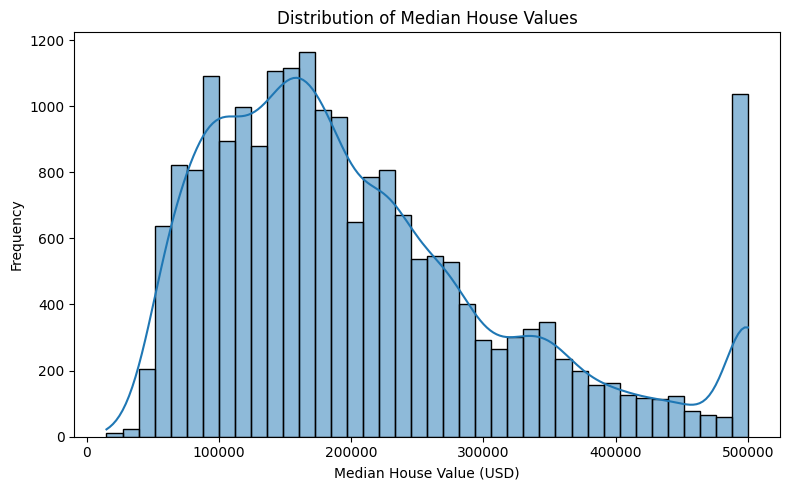

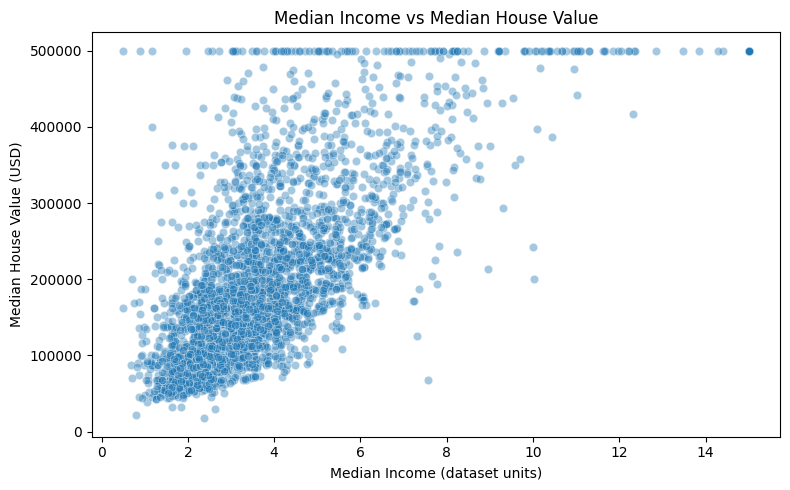

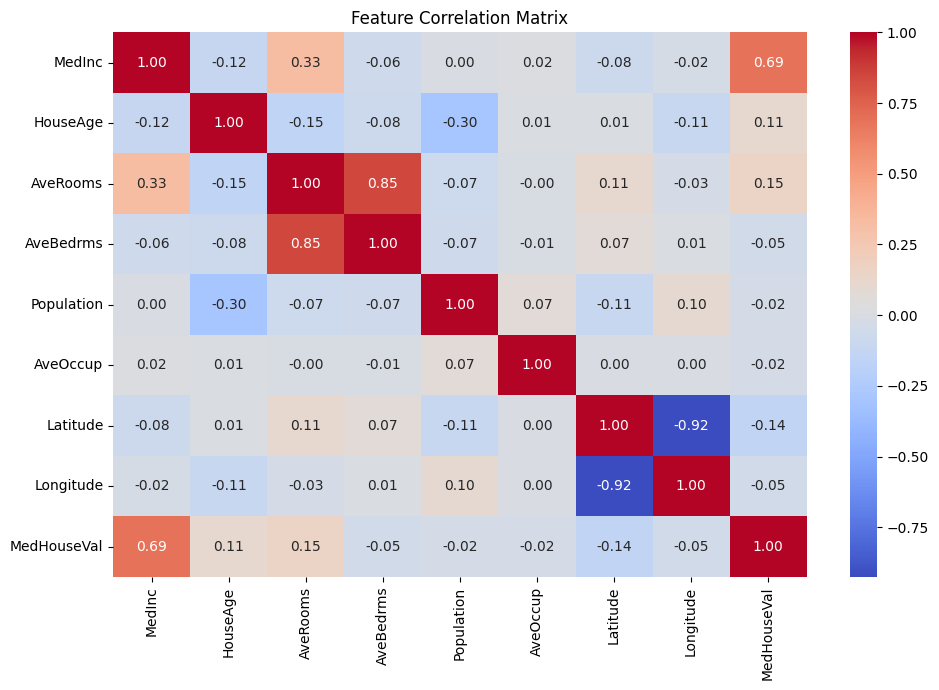

In [ ]:

plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (USD)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(min(3000, len(df)), random_state=42),
    x="MedInc",
    y="MedHouseVal",
    alpha=0.4
)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (dataset units)")
plt.ylabel("Median House Value (USD)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


### Cell 6 - Feature engineering

In [ ]:

df["BedroomsPerRoom"] = (
    df["AveBedrms"] / df["AveRooms"].replace(0, np.nan)
)

df["RoomsPerOccupant"] = (
    df["AveRooms"] / df["AveOccup"].replace(0, np.nan)
)

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Engineered features added successfully.")
display(df.head())


Engineered features added successfully.


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,BedroomsPerRoom,RoomsPerOccupant
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,452600.0,0.146591,2.732919
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,358500.0,0.155797,2.956685
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,352100.0,0.129516,2.957661
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,341300.0,0.184458,2.283154
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,342200.0,0.172096,2.879646


### Cell 7 - Split features and target

In [ ]:

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

numeric_features = X.columns.tolist()

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X.shape[1])


Training samples: 16512
Testing samples: 4128
Number of features: 10


### Cell 8 - Build preprocessing and regression models

In [ ]:

def make_pipeline(regressor, scale=False):
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", regressor))

    return Pipeline(steps)

models = {
    "Linear Regression": make_pipeline(
        LinearRegression(), scale=True
    ),
    "Ridge Regression": make_pipeline(
        Ridge(alpha=1.0), scale=True
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeRegressor(
            max_depth=15,
            random_state=42
        )
    ),
    "Random Forest": make_pipeline(
        RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    ),
    "Gradient Boosting": make_pipeline(
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
    )
}

print("Models and preprocessing pipelines created.")


Models and preprocessing pipelines created.


### Cell 9 - Train all models

In [ ]:

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

print("All models trained successfully.")


Training Linear Regression...
Training Ridge Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
All models trained successfully.


### Cell 10 - Compare MAE, RMSE and R²

In [ ]:

results_df = pd.DataFrame(results).sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(2))

best_model_name = results_df.iloc[0]["Model"]
print("Best model by test RMSE:", best_model_name)


,Model,MAE,RMSE,R2
0,Random Forest,32803.93,50544.29,0.81
1,Gradient Boosting,36602.65,53557.32,0.78
2,Linear Regression,48616.44,67534.72,0.65
3,Ridge Regression,48616.43,67535.59,0.65
4,Decision Tree,44038.44,68568.15,0.64


Best model by test RMSE: Random Forest


### Cell 11 - Visualize model performance

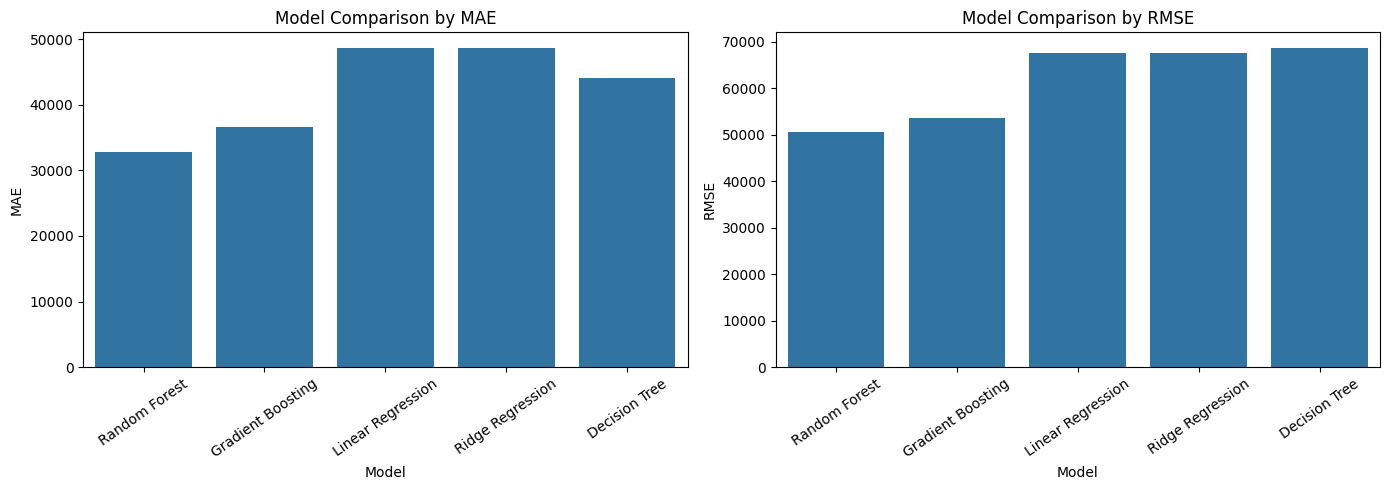

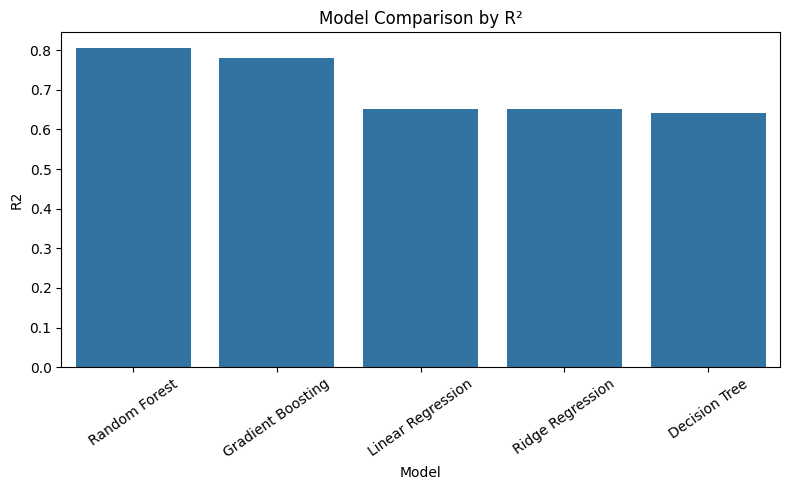

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)
axes[0].set_title("Model Comparison by MAE")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("Model Comparison by RMSE")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="R2")
plt.title("Model Comparison by R²")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


### Cell 12 - Actual vs predicted prices

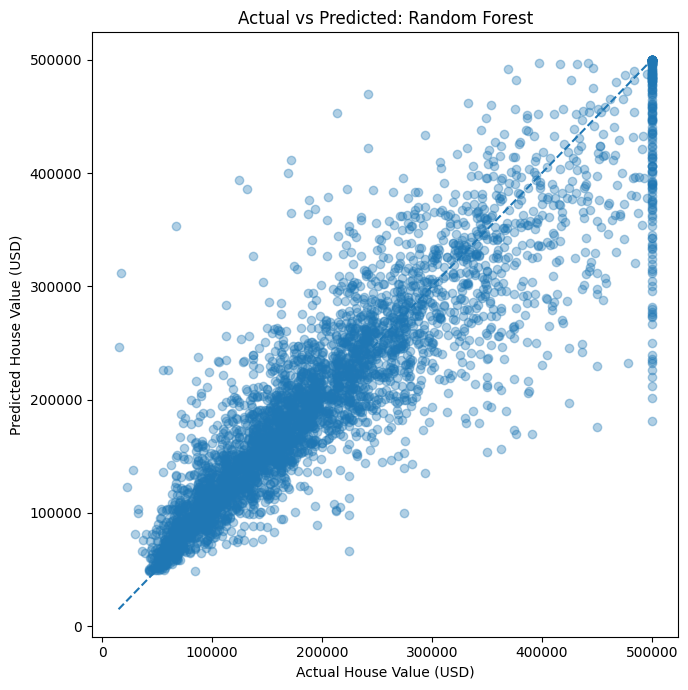

In [ ]:

best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.35)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Value (USD)")
plt.ylabel("Predicted House Value (USD)")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()


### Cell 13 - Cross-validation

Here, cross-validation will be performed only on the training data. The test set will be kept separate for final evaluation.

In [ ]:

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results = []

for name, model in models.items():
    print(f"Cross-validating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "MAE Mean": -scores["test_mae"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "RMSE Mean": -scores["test_rmse"].mean(),
        "RMSE Std": scores["test_rmse"].std(),
        "R2 Mean": scores["test_r2"].mean(),
        "R2 Std": scores["test_r2"].std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="RMSE Mean"
).reset_index(drop=True)

display(cv_results_df.round(2))


Cross-validating Linear Regression...
Cross-validating Ridge Regression...
Cross-validating Decision Tree...
Cross-validating Random Forest...
Cross-validating Gradient Boosting...


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Random Forest,33494.21,482.46,51224.71,1115.09,0.80,0.01
1,Gradient Boosting,36804.72,791.20,52958.96,1275.92,0.79,0.01
2,Ridge Regression,48437.01,976.69,68173.63,2162.05,0.65,0.03
3,Linear Regression,48437.28,976.95,68174.59,2164.20,0.65,0.03
4,Decision Tree,45559.62,1212.07,71769.75,1901.83,0.61,0.02


### Cell 14 - Feature importance

,Feature,Feature Importance
0,MedInc,0.531174
5,AveOccup,0.128173
7,Longitude,0.084160
6,Latitude,0.084061
1,HouseAge,0.051416
8,BedroomsPerRoom,0.026999
9,RoomsPerOccupant,0.024719
4,Population,0.024531
2,AveRooms,0.024106
3,AveBedrms,0.020661


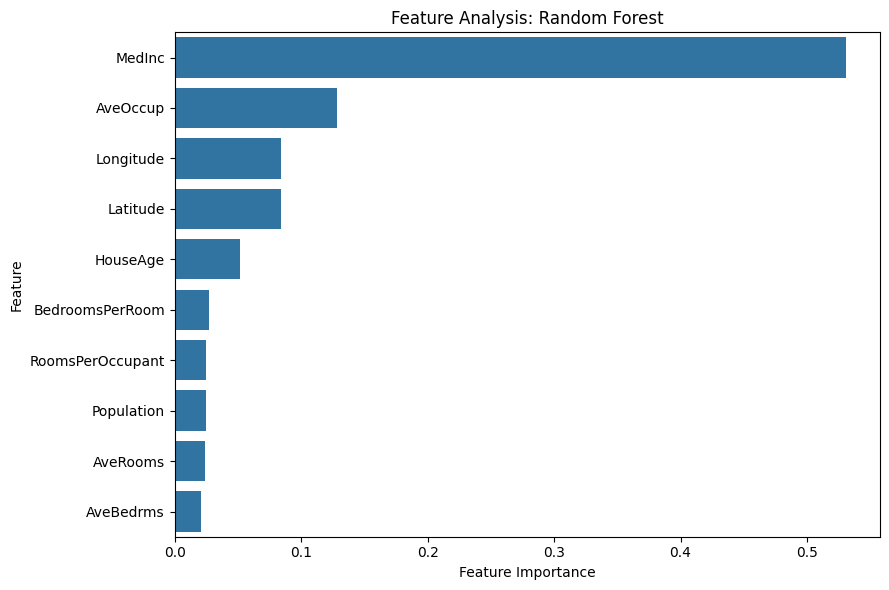

In [ ]:

best_model = trained_models[best_model_name]
regressor = best_model.named_steps["model"]

if hasattr(regressor, "feature_importances_"):
    importance_values = regressor.feature_importances_
    importance_label = "Feature Importance"
elif hasattr(regressor, "coef_"):
    importance_values = np.abs(regressor.coef_)
    importance_label = "Absolute Coefficient"
else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": X.columns,
        importance_label: importance_values
    }).sort_values(
        by=importance_label,
        ascending=False
    )

    display(importance_df)

    plt.figure(figsize=(9, 6))
    sns.barplot(
        data=importance_df,
        x=importance_label,
        y="Feature"
    )
    plt.title(f"Feature Analysis: {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is not available for this model.")


### Cell 15 - Export evaluation results

In [ ]:

results_df.to_csv("house_price_model_comparison.csv", index=False)
cv_results_df.to_csv("house_price_cross_validation.csv", index=False)

print("Saved:")
print("- house_price_model_comparison.csv")
print("- house_price_cross_validation.csv")


Saved:
- house_price_model_comparison.csv
- house_price_cross_validation.csv


### Cell 16 - Predict a sample house value

In [ ]:

sample_house = X_test.iloc[[0]]

actual_price = y_test.iloc[0]
predicted_price = trained_models[best_model_name].predict(sample_house)[0]

print("Model:", best_model_name)
print(f"Actual value: ${actual_price:,.2f}")
print(f"Predicted value: ${predicted_price:,.2f}")
print(f"Absolute error: ${abs(actual_price - predicted_price):,.2f}")

display(sample_house)


Model: Random Forest
Actual value: $47,700.00
Predicted value: $49,250.23
Absolute error: $1,550.23


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,BedroomsPerRoom,RoomsPerOccupant
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.243854,1.081178


Cell 17 - Generate analysis from your actual results

In [ ]:

best_mae_model = results_df.loc[results_df["MAE"].idxmin()]
best_rmse_model = results_df.loc[results_df["RMSE"].idxmin()]
best_r2_model = results_df.loc[results_df["R2"].idxmax()]

print("RESULTS ANALYSIS")
print("=" * 55)

print(
    f"Lowest MAE: {best_mae_model['Model']} "
    f"(${best_mae_model['MAE']:,.2f})"
)

print(
    f"Lowest RMSE: {best_rmse_model['Model']} "
    f"(${best_rmse_model['RMSE']:,.2f})"
)

print(
    f"Highest R²: {best_r2_model['Model']} "
    f"({best_r2_model['R2']:.4f})"
)

print("\nHoldout test results:")
display(results_df.round(2))

print("\nCross-validation results:")
display(cv_results_df.round(2))


RESULTS ANALYSIS
Lowest MAE: Random Forest ($32,803.93)
Lowest RMSE: Random Forest ($50,544.29)
Highest R²: Random Forest (0.8050)

Holdout test results:


,Model,MAE,RMSE,R2
0,Random Forest,32803.93,50544.29,0.81
1,Gradient Boosting,36602.65,53557.32,0.78
2,Linear Regression,48616.44,67534.72,0.65
3,Ridge Regression,48616.43,67535.59,0.65
4,Decision Tree,44038.44,68568.15,0.64



Cross-validation results:


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Random Forest,33494.21,482.46,51224.71,1115.09,0.80,0.01
1,Gradient Boosting,36804.72,791.20,52958.96,1275.92,0.79,0.01
2,Ridge Regression,48437.01,976.69,68173.63,2162.05,0.65,0.03
3,Linear Regression,48437.28,976.95,68174.59,2164.20,0.65,0.03
4,Decision Tree,45559.62,1212.07,71769.75,1901.83,0.61,0.02


## Results Analysis and Discussion

#### Model Performance

Five regression models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). Random Forest achieved the strongest holdout test performance among the evaluated models, with an MAE of $32,803.93, an RMSE of $50,544.29, and an R² of 0.81.

Gradient Boosting ranked second, achieving an MAE of $36,602.65, an RMSE of $53,557.32, and an R² of 0.78. Linear Regression and Ridge Regression achieved similar results, with R² values of approximately 0.65. Decision Tree produced the weakest holdout R² of 0.64.

#### Cross-Validation Findings

Five-fold cross-validation was performed on the training data. Random Forest achieved a mean MAE of $33,494.21, a mean RMSE of $51,224.71, and a mean R² of 0.80. The relatively small reported standard deviations suggest that its performance was reasonably consistent across the five folds.

Gradient Boosting also performed consistently, with a mean R² of 0.79. These cross-validation findings broadly agree with the holdout evaluation and support Random Forest as the strongest model in this experiment.

#### Feature Importance

Random Forest identified median income (MedInc) as the most influential feature, with an importance score of approximately 0.531. Average occupancy (AveOccup) followed at approximately 0.128. Longitude and latitude each contributed approximately 0.084.

These results indicate that income and geographic location were important predictors within this dataset. Feature importance describes the model's use of predictive information; it does not establish causation.

### Sample Prediction

For one test sample, the actual median house value was $47,700.00, while the predicted value was $49,250.23. The absolute error was $1,550.23. This illustrates a relatively close prediction for that individual sample, although individual predictions can differ substantially from the overall model performance.

#### Limitations

The dataset represents California housing rather than the entire housing market. Its target values are capped at $500,000, which limits the model's ability to estimate values above that threshold. Results may not generalize to other locations or time periods.

#### Conclusion

Random Forest was the best-performing model among the five regressors evaluated in this experiment. It achieved the lowest holdout MAE and RMSE, the highest holdout R², and the strongest mean cross-validation performance. The project demonstrates a practical regression workflow involving exploratory data analysis, feature engineering, preprocessing, model comparison, cross-validation, and feature-importance analysis.